# Human or AI? Text Authorship Classification


## 1. Environment Setup and Configuration


### 1.1 Install and Import Dependencies


In [1]:
import sys
import json
import random
import zipfile
from io import BytesIO
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Dependencies imported successfully.")

Python: 3.9.6
NumPy: 1.26.4
Pandas: 2.3.2
Scikit-learn: 1.6.1
Dependencies imported successfully.


### 1.2 Configure Data and Output Paths


In [3]:
from pathlib import Path

# Detect whether the notebook is running in Google Colab.
try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/human_or_ai")
    DATA_DIR = PROJECT_DIR / "data"
else:
    # Support running from either the project root or Code/.
    current_dir = Path.cwd()
    PROJECT_DIR = next(
        (folder for folder in [current_dir, *current_dir.parents]
         if (folder / "Data").is_dir()),
        None,
    )

    if PROJECT_DIR is None:
        raise FileNotFoundError(
            f"Cannot find a Data folder in {current_dir} or its parents."
        )

    DATA_DIR = PROJECT_DIR / "Data"

OUTPUT_DIR = PROJECT_DIR / "outputs"
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
UNLABELED_PATH = DATA_DIR / "unlabeled.csv"
STARTER_PATH = DATA_DIR / "train_starter_2000.csv"
SAMPLE_SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"

print("Data folder:", DATA_DIR.resolve())
print("Output folder:", OUTPUT_DIR.resolve())

for name in REQUIRED_FILES:
    size_mb = (DATA_DIR / name).stat().st_size / 1_000_000
    print(f"  {name}: {size_mb:.3f} MB")

print("All five competition files are ready.")

Data folder: /Users/zhanghaoxiang/Desktop/CS5785-AML-Kaggle-Challenge/Data
Output folder: /Users/zhanghaoxiang/Desktop/CS5785-AML-Kaggle-Challenge/outputs
  train.csv: 12.749 MB
  test.csv: 3.866 MB
  unlabeled.csv: 3.842 MB
  train_starter_2000.csv: 2.568 MB
  sample_submission.csv: 0.030 MB
All five competition files are ready.


### 1.3 Set Random Seeds and Experiment Parameters


In [5]:
import sys
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

# Ensure the output folder exists on both Colab and local machines.
OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Reproducible experiment settings.
SEED = 42
VALIDATION_SIZE = 2000
TRAINING_SIZES = [500, 1000, 2000, 5000, 8000]
DECISION_THRESHOLD = 0.5

random.seed(SEED)
np.random.seed(SEED)

# Also pass random_state=SEED to splits and estimators that support it.
CONFIG = {
    "seed": SEED,
    "validation_size": VALIDATION_SIZE,
    "training_sizes": TRAINING_SIZES,
    "decision_threshold": DECISION_THRESHOLD,
    "metric": "roc_auc",
    "label_mapping": {"human": 0, "ai": 1},
    "data_dir": str(Path(DATA_DIR).resolve()),
    "output_dir": str(OUTPUT_DIR.resolve()),
}

VERSIONS = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
}

CONFIG_PATH = OUTPUT_DIR / "config.json"
ENVIRONMENT_PATH = OUTPUT_DIR / "environment.json"

CONFIG_PATH.write_text(
    json.dumps(CONFIG, indent=2),
    encoding="utf-8",
)
ENVIRONMENT_PATH.write_text(
    json.dumps(VERSIONS, indent=2),
    encoding="utf-8",
)

print("Experiment configuration:")
print(json.dumps(CONFIG, indent=2))

print("\nPackage versions:")
print(json.dumps(VERSIONS, indent=2))

print("\nSaved files:")
print(CONFIG_PATH.resolve())
print(ENVIRONMENT_PATH.resolve())

Experiment configuration:
{
  "seed": 42,
  "validation_size": 2000,
  "training_sizes": [
    500,
    1000,
    2000,
    5000,
    8000
  ],
  "decision_threshold": 0.5,
  "metric": "roc_auc",
  "label_mapping": {
    "human": 0,
    "ai": 1
  },
  "data_dir": "/Users/zhanghaoxiang/Desktop/CS5785-AML-Kaggle-Challenge/Data",
  "output_dir": "/Users/zhanghaoxiang/Desktop/CS5785-AML-Kaggle-Challenge/outputs"
}

Package versions:
{
  "python": "3.9.6",
  "numpy": "1.26.4",
  "pandas": "2.3.2",
  "scikit_learn": "1.6.1"
}

Saved files:
/Users/zhanghaoxiang/Desktop/CS5785-AML-Kaggle-Challenge/outputs/config.json
/Users/zhanghaoxiang/Desktop/CS5785-AML-Kaggle-Challenge/outputs/environment.json


## 2. Data Loading and Exploration


### 2.1 Load the Datasets


In [6]:
import pandas as pd
from IPython.display import display

# Read each CSV once and keep the dataframes for later sections.
datasets = {
    filename: pd.read_csv(DATA_DIR / filename)
    for filename in REQUIRED_FILES
}

train_df = datasets["train.csv"]
test_df = datasets["test.csv"]
unlabeled_df = datasets["unlabeled.csv"]
starter_df = datasets["train_starter_2000.csv"]
sample_submission_df = datasets["sample_submission.csv"]

dataset_summary = pd.DataFrame([
    {
        "Dataset": filename,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Headers": ", ".join(df.columns),
        "File size (MB)": (DATA_DIR / filename).stat().st_size / 1_000_000,
    }
    for filename, df in datasets.items()
])

display(dataset_summary.style.format({
    "Rows": "{:,}",
    "Columns": "{:d}",
    "File size (MB)": "{:.3f}",
}).hide(axis="index"))

print("Row counts exclude the header. 1 MB = 1,000,000 bytes.")
print("train_starter_2000.csv is a subset of train.csv; do not combine them as extra training data.")


Dataset,Rows,Columns,Headers,File size (MB)
train.csv,"10,000",3,"id, text, label",12.749
test.csv,"3,000",2,"id, text",3.866
unlabeled.csv,"3,000",2,"id, text",3.842
train_starter_2000.csv,"2,000",3,"id, text, label",2.568
sample_submission.csv,"3,000",2,"id, label",0.030


Row counts exclude the header. 1 MB = 1,000,000 bytes.
train_starter_2000.csv is a subset of train.csv; do not combine them as extra training data.


### 2.2 Inspect Data Structure and Class Distribution


,Dataset,Column,Data type,Non-null rows
0,train.csv,id,int64,10000
1,train.csv,text,object,10000
2,train.csv,label,int64,10000
3,test.csv,id,int64,3000
4,test.csv,text,object,3000
5,unlabeled.csv,id,int64,3000
6,unlabeled.csv,text,object,3000
7,train_starter_2000.csv,id,int64,2000
8,train_starter_2000.csv,text,object,2000
9,train_starter_2000.csv,label,int64,2000


,Dataset,Label,Class,Rows,Share (%)
0,train.csv,0,Human,5000,50.0
1,train.csv,1,AI,5000,50.0
2,train_starter_2000.csv,0,Human,1000,50.0
3,train_starter_2000.csv,1,AI,1000,50.0


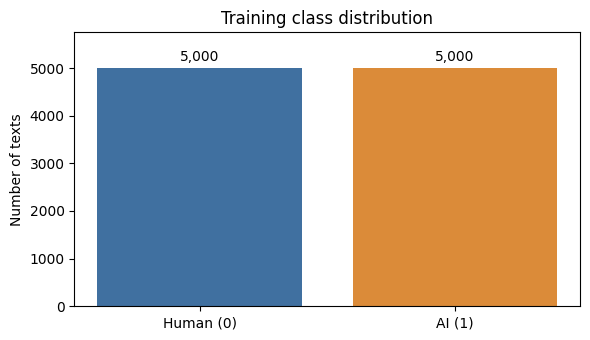

Human = 0; AI = 1. Test and unlabeled data have no ground-truth labels.
The 0.5 values in sample_submission.csv are placeholders, not class labels.


In [7]:
# Inspect the original columns without modifying any source dataframe.
expected_columns = {
    "train.csv": ["id", "text", "label"],
    "test.csv": ["id", "text"],
    "unlabeled.csv": ["id", "text"],
    "train_starter_2000.csv": ["id", "text", "label"],
    "sample_submission.csv": ["id", "label"],
}
for filename, expected in expected_columns.items():
    assert datasets[filename].columns.tolist() == expected, filename

schema_summary = pd.DataFrame([
    {"Dataset": filename, "Column": column,
     "Data type": str(df[column].dtype), "Non-null rows": int(df[column].notna().sum())}
    for filename, df in datasets.items() for column in df.columns
])
display(schema_summary)

LABEL_NAMES = {0: "Human", 1: "AI"}
class_rows = []
for filename in ["train.csv", "train_starter_2000.csv"]:
    labels = datasets[filename]["label"]
    assert labels.notna().all() and labels.isin([0, 1]).all(), filename
    for label, count in labels.value_counts().sort_index().items():
        class_rows.append({"Dataset": filename, "Label": label,
                           "Class": LABEL_NAMES[label], "Rows": count,
                           "Share (%)": 100 * count / len(labels)})
class_distribution = pd.DataFrame(class_rows)
display(class_distribution)

fig, ax = plt.subplots(figsize=(6, 3.5))
counts = train_df["label"].value_counts().reindex([0, 1], fill_value=0)
bars = ax.bar(["Human (0)", "AI (1)"], counts, color=["#4070A0", "#DB8B39"])
ax.bar_label(bars, labels=[f"{n:,}" for n in counts], padding=3)
ax.set(title="Training class distribution", ylabel="Number of texts", ylim=(0, counts.max() * 1.15))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "class_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

schema_summary.to_csv(OUTPUT_DIR / "dataset_schema.csv", index=False)
class_distribution.to_csv(OUTPUT_DIR / "class_distribution.csv", index=False)
print("Human = 0; AI = 1. Test and unlabeled data have no ground-truth labels.")
print("The 0.5 values in sample_submission.csv are placeholders, not class labels.")


### 2.3 Check Missing Values and Duplicate Texts


In [8]:
# Normalization is only for duplicate checks; original text stays unchanged.
def normalize_for_audit(text):
    return text.astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.lower()

missing_summary = pd.DataFrame([
    {"Dataset": name, "Column": column, "Missing": int(df[column].isna().sum())}
    for name, df in datasets.items() for column in df.columns
])
audit_rows = []
for name, df in datasets.items():
    row = {"Dataset": name, "Missing cells": int(df.isna().sum().sum()),
           "Duplicate rows": int(df.duplicated().sum()),
           "Duplicate IDs": int(df["id"].duplicated().sum()),
           "Blank texts": pd.NA, "Duplicate texts": pd.NA,
           "Normalized duplicate texts": pd.NA}
    if "text" in df:
        text = df["text"].dropna()
        row.update({"Blank texts": int(text.str.strip().eq("").sum()),
                    "Duplicate texts": int(text.duplicated().sum()),
                    "Normalized duplicate texts": int(normalize_for_audit(text).duplicated().sum())})
    audit_rows.append(row)
quality_summary = pd.DataFrame(audit_rows)
display(missing_summary)
display(quality_summary.fillna("N/A"))
print("Duplicate counts are extra occurrences after the first; N/A means there is no text column.")

pairs = [("train.csv", "test.csv"), ("train.csv", "unlabeled.csv"),
         ("test.csv", "unlabeled.csv"), ("train.csv", "train_starter_2000.csv")]
overlap_rows = []
for left, right in pairs:
    a, b = datasets[left], datasets[right]
    overlap_rows.append({"Left dataset": left, "Right dataset": right,
        "Shared IDs": len(set(a["id"]) & set(b["id"])),
        "Shared normalized texts": len(set(normalize_for_audit(a["text"]).dropna()) &
                                       set(normalize_for_audit(b["text"]).dropna()))})
overlap_summary = pd.DataFrame(overlap_rows)
display(overlap_summary)

assert quality_summary["Missing cells"].eq(0).all(), "Review missing data before modeling."
assert quality_summary["Duplicate IDs"].eq(0).all(), "Review duplicate IDs before splitting."
assert quality_summary["Blank texts"].dropna().eq(0).all(), "Review blank text before modeling."
assert sample_submission_df["id"].equals(test_df["id"]), "Submission IDs/order differ from test."
starter_match = starter_df.merge(train_df, on=["id", "text", "label"], validate="one_to_one")
assert len(starter_match) == len(starter_df), "Starter data is not an exact training subset."

missing_summary.to_csv(OUTPUT_DIR / "missing_values.csv", index=False)
quality_summary.to_csv(OUTPUT_DIR / "data_quality.csv", index=False)
overlap_summary.to_csv(OUTPUT_DIR / "dataset_overlap.csv", index=False)
print("Data integrity checks passed. No rows were removed or changed.")
print("Starter overlap is expected: all 2,000 starter rows already belong to train.csv.")
print("This audit detects exact and case/whitespace-normalized matches, not semantic near-duplicates.")


,Dataset,Column,Missing
0,train.csv,id,0
1,train.csv,text,0
2,train.csv,label,0
3,test.csv,id,0
4,test.csv,text,0
5,unlabeled.csv,id,0
6,unlabeled.csv,text,0
7,train_starter_2000.csv,id,0
8,train_starter_2000.csv,text,0
9,train_starter_2000.csv,label,0


,Dataset,Missing cells,Duplicate rows,Duplicate IDs,Blank texts,Duplicate texts,Normalized duplicate texts
0,train.csv,0,0,0,0,0,0
1,test.csv,0,0,0,0,0,0
2,unlabeled.csv,0,0,0,0,0,0
3,train_starter_2000.csv,0,0,0,0,0,0
4,sample_submission.csv,0,0,0,N/A,N/A,N/A


Duplicate counts are extra occurrences after the first; N/A means there is no text column.


,Left dataset,Right dataset,Shared IDs,Shared normalized texts
0,train.csv,test.csv,0,0
1,train.csv,unlabeled.csv,0,0
2,test.csv,unlabeled.csv,0,0
3,train.csv,train_starter_2000.csv,2000,2000


Data integrity checks passed. No rows were removed or changed.
Starter overlap is expected: all 2,000 starter rows already belong to train.csv.
This audit detects exact and case/whitespace-normalized matches, not semantic near-duplicates.


### 2.4 Explore Text Length Distributions


,Dataset,Rows,Mean_words,Median_words,Min_words,P90_words,P95_words,Max_words,Mean_characters,Median_characters,Min_characters,Max_characters
0,train.csv,10000,208.7,206.0,75,295.0,316.0,350,1260.9,1246.0,331,2938
1,test.csv,3000,217.0,213.0,75,301.0,323.0,350,1274.9,1247.0,365,2631
2,unlabeled.csv,3000,210.3,206.5,75,303.1,324.0,350,1268.1,1260.0,363,2608
3,train_starter_2000.csv,2000,209.9,207.0,76,297.1,318.0,349,1269.3,1250.0,361,2607


,Class,Rows,Mean_words,Median_words,Mean_characters,Median_characters
0,AI,5000,208.4,209.0,1282.8,1278.0
1,Human,5000,209.0,204.0,1239.0,1222.0


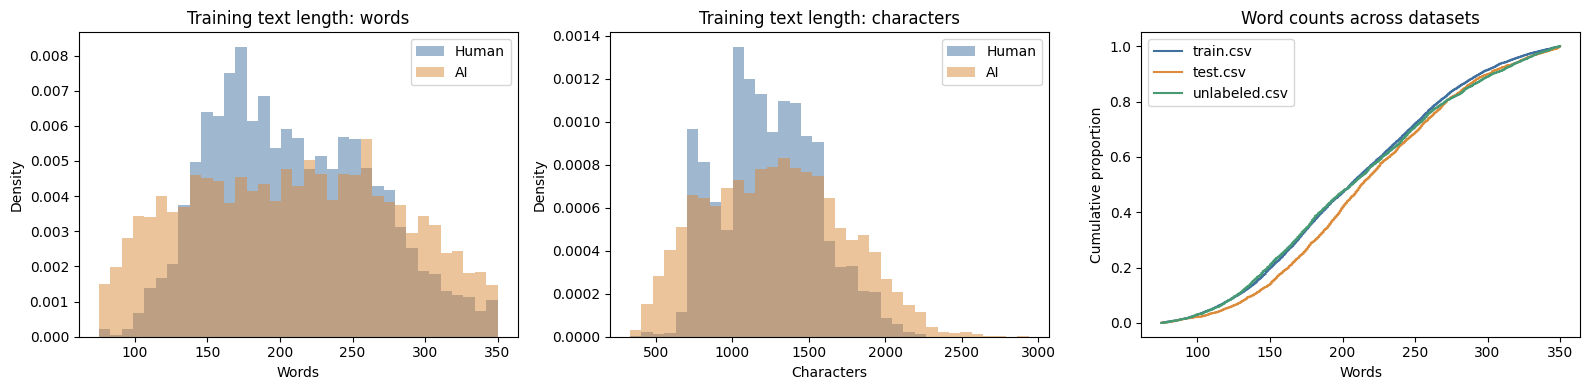

sample_submission.csv has no text, so it is excluded from length analysis.
The starter subset is reported in the table but excluded from the cross-dataset plot.
These are descriptive summaries. Similar lengths alone do not establish similar writing styles.
Any learned preprocessing or later length-bin cutoffs must use only the training split.


In [9]:
# Words = whitespace-separated tokens; characters include spaces/punctuation.
# Keep these descriptive features separate from the original model inputs.
length_frames = []
for name, df in datasets.items():
    if "text" not in df:
        continue
    lengths = pd.DataFrame({"Dataset": name, "id": df["id"],
        "words": df["text"].str.count(r"\S+"),
        "characters": df["text"].str.len()})
    lengths["Class"] = df["label"].map(LABEL_NAMES) if "label" in df else "Unknown"
    length_frames.append(lengths)
length_data = pd.concat(length_frames, ignore_index=True)

length_summary = length_data.groupby("Dataset", sort=False).agg(
    Rows=("id", "size"), Mean_words=("words", "mean"),
    Median_words=("words", "median"), Min_words=("words", "min"),
    P90_words=("words", lambda x: x.quantile(0.90)),
    P95_words=("words", lambda x: x.quantile(0.95)), Max_words=("words", "max"),
    Mean_characters=("characters", "mean"), Median_characters=("characters", "median"),
    Min_characters=("characters", "min"), Max_characters=("characters", "max")
).reset_index()
display(length_summary.round(1))
train_lengths = length_data[length_data["Dataset"].eq("train.csv")]
class_length_summary = train_lengths.groupby("Class").agg(
    Rows=("id", "size"), Mean_words=("words", "mean"), Median_words=("words", "median"),
    Mean_characters=("characters", "mean"), Median_characters=("characters", "median")
).reset_index()
display(class_length_summary.round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for feature, ax in zip(["words", "characters"], axes[:2]):
    bins = np.histogram_bin_edges(train_lengths[feature], bins=35)
    for label, color in [("Human", "#4070A0"), ("AI", "#DB8B39")]:
        values = train_lengths.loc[train_lengths["Class"].eq(label), feature]
        ax.hist(values, bins=bins, density=True, alpha=0.5, label=label, color=color)
    ax.set(title=f"Training text length: {feature}", xlabel=feature.capitalize(), ylabel="Density")
    ax.legend()
for name, color in [("train.csv", "#4070A0"), ("test.csv", "#DB8B39"), ("unlabeled.csv", "#469A74")]:
    values = np.sort(length_data.loc[length_data["Dataset"].eq(name), "words"].to_numpy())
    axes[2].step(values, np.arange(1, len(values) + 1) / len(values),
                 where="post", label=name, color=color)
axes[2].set(title="Word counts across datasets", xlabel="Words", ylabel="Cumulative proportion")
axes[2].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "text_length_distributions.png", dpi=160, bbox_inches="tight")
plt.show()
length_summary.to_csv(OUTPUT_DIR / "text_length_summary.csv", index=False)
class_length_summary.to_csv(OUTPUT_DIR / "class_length_summary.csv", index=False)
print("sample_submission.csv has no text, so it is excluded from length analysis.")
print("The starter subset is reported in the table but excluded from the cross-dataset plot.")
print("These are descriptive summaries. Similar lengths alone do not establish similar writing styles.")
print("Any learned preprocessing or later length-bin cutoffs must use only the training split.")


### 2.5 Create a Fixed Stratified Training–Validation Split


In [10]:
import hashlib

# Freeze a single stratified split for every later experiment.
assert len(train_df) == 10000 and VALIDATION_SIZE == 2000
assert train_df["id"].is_unique and train_df["id"].notna().all()
SPLIT_PATH = OUTPUT_DIR / "split_assignments.csv"
SPLIT_META_PATH = OUTPUT_DIR / "split_metadata.json"
expected_metadata = {
    "seed": SEED, "validation_size": VALIDATION_SIZE,
    "train_csv_sha256": hashlib.sha256(TRAIN_PATH.read_bytes()).hexdigest(),
}
assert SPLIT_PATH.exists() == SPLIT_META_PATH.exists(), "Incomplete saved split; review output files."
reuse_split = SPLIT_PATH.exists()
if reuse_split:
    split_metadata = json.loads(SPLIT_META_PATH.read_text())
    assert all(split_metadata.get(k) == v for k, v in expected_metadata.items()), (
        "Data or split settings changed. Keep the existing split intact and review the mismatch."
    )
    split_assignments = pd.read_csv(SPLIT_PATH, dtype={"id": train_df["id"].dtype})
else:
    train_ids, val_ids = train_test_split(
        train_df["id"].to_numpy(), test_size=VALIDATION_SIZE,
        stratify=train_df["label"].to_numpy(), random_state=SEED,
    )
    split_assignments = pd.concat([
        pd.DataFrame({"id": train_ids, "split": "train"}),
        pd.DataFrame({"id": val_ids, "split": "validation"}),
    ], ignore_index=True)

assert split_assignments.columns.tolist() == ["id", "split"]
assert split_assignments["id"].is_unique and len(split_assignments) == len(train_df)
assert set(split_assignments["id"]) == set(train_df["id"])
assert set(split_assignments["split"]) == {"train", "validation"}
train_ids = split_assignments.loc[split_assignments["split"].eq("train"), "id"].to_numpy()
val_ids = split_assignments.loc[split_assignments["split"].eq("validation"), "id"].to_numpy()
indexed_train = train_df.set_index("id", drop=False)
train_split = indexed_train.loc[train_ids].reset_index(drop=True).copy()
val_split = indexed_train.loc[val_ids].reset_index(drop=True).copy()

assert len(train_split) == 8000 and len(val_split) == 2000
assert not (set(train_ids) & set(val_ids))
assert train_split["label"].value_counts().to_dict() == {0: 4000, 1: 4000}
assert val_split["label"].value_counts().to_dict() == {0: 1000, 1: 1000}
shared_texts = set(normalize_for_audit(train_split["text"])) & set(normalize_for_audit(val_split["text"]))
assert not shared_texts, "Duplicate text crosses the split; review before training."
assert max(TRAINING_SIZES) <= len(train_split)

if not reuse_split:
    split_assignments.to_csv(SPLIT_PATH, index=False)
    SPLIT_META_PATH.write_text(json.dumps({**expected_metadata,
        "sklearn_version": sklearn.__version__, "method": "stratified train_test_split"}, indent=2))

X_train, y_train = train_split["text"].copy(), train_split["label"].copy()
X_val, y_val = val_split["text"].copy(), val_split["label"].copy()
split_summary = pd.DataFrame([
    {"Split": name, "Rows": len(df), "Human (0)": int(df["label"].eq(0).sum()),
     "AI (1)": int(df["label"].eq(1).sum()), "AI share (%)": 100 * df["label"].mean()}
    for name, df in [("Train", train_split), ("Validation", val_split)]
])
display(split_summary)
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)
print("Reused the saved split." if reuse_split else "Created and saved the fixed split.")
print("ID overlap: 0; normalized-text overlap: 0.")
print("Split assignments:", SPLIT_PATH)
print("Fit vectorizers and other learned preprocessing on X_train only.")
print("Keep X_val/y_val fixed for all experiments; do not train or pseudo-label with validation rows.")
print("Test/unlabeled rows and the starter subset were not added to this split.")


,Split,Rows,Human (0),AI (1),AI share (%)
0,Train,8000,4000,4000,50.0
1,Validation,2000,1000,1000,50.0


Created and saved the fixed split.
ID overlap: 0; normalized-text overlap: 0.
Split assignments: /Users/zhanghaoxiang/Desktop/CS5785-AML-Kaggle-Challenge/outputs/split_assignments.csv
Fit vectorizers and other learned preprocessing on X_train only.
Keep X_val/y_val fixed for all experiments; do not train or pseudo-label with validation rows.
Test/unlabeled rows and the starter subset were not added to this split.


## 3. Baseline Model


### 3.1 Text Preprocessing


### 3.2 TF-IDF Feature Extraction


### 3.3 Train a Logistic Regression Baseline


### 3.4 Define Reusable Evaluation Functions


### 3.5 Evaluate and Record Baseline Performance


## 4. Model Comparison and Hyperparameter Tuning


### 4.1 Define Candidate Models


### 4.2 Establish a Fair Comparison Protocol


### 4.3 Tune Hyperparameters for at Least Two Models


### 4.4 Compare Training AUROC, Validation AUROC, and Runtime


### 4.5 Select the Best Model Configuration


## 5. Effect of Training Data Size


### 5.1 Define the Controlled Experiment


### 5.2 Construct Training Subsets


### 5.3 Train and Evaluate Each Subset


### 5.4 Plot Training and Validation Learning Curves


### 5.5 Interpret Overfitting, Underfitting, and Data Efficiency


## 6. Learning from Unlabeled Data


### 6.1 Define the Semi-Supervised Learning Method


### 6.2 Generate and Select Pseudo-Labels


### 6.3 Retrain with Labeled and Pseudo-Labeled Data


### 6.4 Compare Against the Supervised Baseline


### 6.5 Discuss Pseudo-Label Noise and Validation Leakage Prevention


## 7. Generalization and Error Analysis


### 7.1 Analyze the Training–Validation Performance Gap


### 7.2 Evaluate Performance Across Text Length Groups


### 7.3 Define the Classification Threshold


### 7.4 Analyze Five False Positives


### 7.5 Analyze Five False Negatives


### 7.6 Identify Recurring Failure Patterns and Potential Remedies


## 8. Open-Ended Improvement Experiment


### 8.1 State the Hypothesis and Motivation


### 8.2 Describe the Proposed Improvement


### 8.3 Define the Baseline and Controlled Variables


### 8.4 Compare Validation Performance and Runtime


### 8.5 Discuss Findings, Limitations, and Next Steps


## 9. Final Model Training and Kaggle Submission


### 9.1 Confirm the Final Modeling Approach


### 9.2 Retrain on All Labeled Data


### 9.3 Generate Test-Set Probabilities


### 9.4 Validate and Export the Submission File


### 9.5 Record Kaggle Public and Private Scores


## 10. Results Export, Reproducibility, and Documentation


### 10.1 Summarize the Final Pipeline and Results


### 10.2 Export Experiment Tables and Figures


### 10.3 Document Dependencies, Random Seeds, and Execution Instructions


### 10.4 Link the GitHub Pull Request and Meaningful Development Commits


### 10.5 Document Team Contributions and AI Assistance


### 10.6 Complete the Final Submission Checklist
